# 6.4 Температура, тепловой поток и эффективная теплопроводность

# 6.4 温度、热流与有效热导率

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})

Matplotlib is building the font cache; this may take a moment.


## Двухскоростная gray-модель
Частица входит слева с направлением +1. После каждого рассеяния новое направление выбирается из −1 и +1 с равными вероятностями, включая прежнее направление. Границы поглощают выходящие частицы.

В расчёте $x^*=x/(v\tau)$, $t^*=t/\tau$, $L^*=L/(v\tau)$. Скорость равна ±1, среднее время между событиями равно 1. Это учебная модель с постоянными свойствами, без спектра реального материала.

## 双速度 gray 模型
粒子从左侧以 +1 方向进入。每次散射后，以相同概率从 −1 和 +1 中重新选择方向，也可能保持原方向。粒子到达边界后被吸收。

计算采用 $x^*=x/(v\tau)$、$t^*=t/\tau$、$L^*=L/(v\tau)$，速度为 ±1，平均事件间隔为 1。这是参数恒定的教学模型，不包含真实材料的声子谱。

## Параметры слоя
Используем условные постоянные $C$, $v$ и $\tau$ с единицами СИ. Резервуары имеют температуры 301 K и 299 K. Рассеяние сохраняет энергию пакета.

## 平板参数
使用示例常数 $C$、$v$ 和 $\tau$，单位采用 SI。两侧热库温度为 301 K 和 299 K。散射保持能量包的能量不变。

In [2]:
C = 1.6e6       # J/(m^3 K)
v = 1000.0      # m/s
tau = 1e-10     # s
TL, TR = 301.0, 299.0
DeltaT = TL - TR
mean_free_path = v * tau
length = 5.0
L = length * mean_free_path
k_bulk = C * v**2 * tau
q_ballistic = C * v * DeltaT / 2
print(f"v*tau = {mean_free_path:.2e} m, L = {L:.2e} m")
print(f"k_bulk = {k_bulk:.3f} W/(m K)")

v*tau = 1.00e-07 m, L = 5.00e-07 m
k_bulk = 160.000 W/(m K)


## Равновесный фон и отклонение
Однородный фон $T_R$ учитываем точно. Случайными траекториями переносим только дополнительную энергию от левого резервуара, пропорциональную $\Delta T$. Поэтому не приходится выделять разность 2 K из шума фоновой энергии около 300 K.

Идея моделирования отклонения от равновесия: [Péraud & Hadjiconstantinou, 2011](https://arxiv.org/abs/1109.3910). Ниже используется только наша учебная двухскоростная модель.

## 平衡背景与偏差
均匀的 $T_R$ 背景解析处理，只用随机轨迹输运左侧热库产生的、与 $\Delta T$ 成正比的额外能量，因此不必从约 300 K 背景能量的噪声中提取 2 K 的温差。

平衡偏差模拟的思想参考：[Péraud 与 Hadjiconstantinou，2011](https://arxiv.org/abs/1109.3910)。以下实现仅针对本课程的双速度教学模型。

In [3]:
def event_transport(n, length, rng, n_cells=0):
    x = np.zeros(n)
    direction = np.ones(n)
    alive = np.ones(n, dtype=bool)
    transmitted = np.zeros(n, dtype=bool)
    elapsed = np.zeros(n)
    collisions = np.zeros(n, dtype=int)
    edges = np.linspace(0, length, n_cells + 1)
    residence = np.zeros(n_cells)
    signed_residence = np.zeros(n_cells)
    updates = 0
    while alive.any():
        ids = np.flatnonzero(alive)
        ts = rng.exponential(1.0, ids.size)
        tb = np.where(direction[ids] > 0, length - x[ids], x[ids])
        h = np.minimum(ts, tb)
        old_x = x[ids].copy()
        new_x = np.clip(old_x + direction[ids] * h, 0, length)
        if n_cells:
            lo = np.minimum(old_x, new_x)[:, None]
            hi = np.maximum(old_x, new_x)[:, None]
            overlap = np.maximum(0, np.minimum(hi, edges[1:])
                                 - np.maximum(lo, edges[:-1]))
            residence += overlap.sum(axis=0)
            signed_residence += (overlap * direction[ids, None]).sum(axis=0)
        elapsed[ids] += h
        x[ids] = new_x
        hit = tb <= ts
        transmitted[ids[hit]] = direction[ids[hit]] > 0
        alive[ids[hit]] = False
        scattered = ids[~hit]
        collisions[scattered] += 1
        direction[scattered] = rng.choice([-1.0, 1.0], scattered.size)
        updates += ids.size
    return {"transmitted": transmitted, "time": elapsed,
            "collisions": collisions, "x": x, "updates": updates,
            "residence": residence / n,
            "signed_residence": signed_residence / n}

## Время пребывания в ячейке
Для каждого прямого участка находим длину его пересечения с ячейкой. В безразмерных единицах скорость равна 1, поэтому эта длина равна времени пребывания. Усредняем по всем вошедшим частицам, включая вернувшиеся.

Если $r_j$ — среднее безразмерное время в ячейке ширины $\Delta x^*$, то $T_j=T_R+\Delta T\,r_j/(2\Delta x^*)$. Для потока используем время со знаком направления.

## 空间单元中的停留时间
对每一段直线飞行计算其与空间单元的重叠长度。无量纲速度为 1，因此该长度等于停留时间。对所有进入的粒子取平均，包括返回左侧的粒子。

设 $r_j$ 是粒子在宽度为 $\Delta x^*$ 的单元中的平均无量纲停留时间，则 $T_j=T_R+\Delta T\,r_j/(2\Delta x^*)$。计算热流时使用带方向符号的停留时间。

In [4]:
n_cells = 20
edges = np.linspace(0, length, n_cells + 1)
centers = (edges[:-1] + edges[1:]) / 2
dx = edges[1] - edges[0]
R, N_batch = 20, 4000
T_batches, q_batches, p_batches = [], [], []
rng = np.random.default_rng(2028)
residence_sum, mean_time_sum = 0.0, 0.0
for r in range(R):
    result = event_transport(N_batch, length, rng, n_cells=n_cells)
    T_batches.append(TR + DeltaT * result["residence"] / (2 * dx))
    q_batches.append(q_ballistic * result["signed_residence"] / dx)
    p_batches.append(result["transmitted"].mean())
    residence_sum += result["residence"].sum()
    mean_time_sum += result["time"].mean()
T_batches = np.array(T_batches)
q_batches = np.array(q_batches)
p_batches = np.array(p_batches)
T_mc = T_batches.mean(axis=0)
T_se = T_batches.std(axis=0, ddof=1) / np.sqrt(R)
q_mc = q_ballistic * p_batches.mean()
q_se = q_ballistic * p_batches.std(ddof=1) / np.sqrt(R)
k_eff = q_mc * L / DeltaT
p_exact = 1 / (1 + length / 2)
q_exact = q_ballistic * p_exact
T_exact = TR + DeltaT * (length + 1 - centers) / (length + 2)
print(f"q_MC = {q_mc:.4e} +/- {q_se:.2e} W/m^2 (SE)")
print(f"q_ref = {q_exact:.4e} W/m^2")
print(f"k_eff = {k_eff:.3f} W/(m K)")

q_MC = 4.5784e+08 +/- 1.95e+06 W/m^2 (SE)
q_ref = 4.5714e+08 W/m^2
k_eff = 114.460 W/(m K)


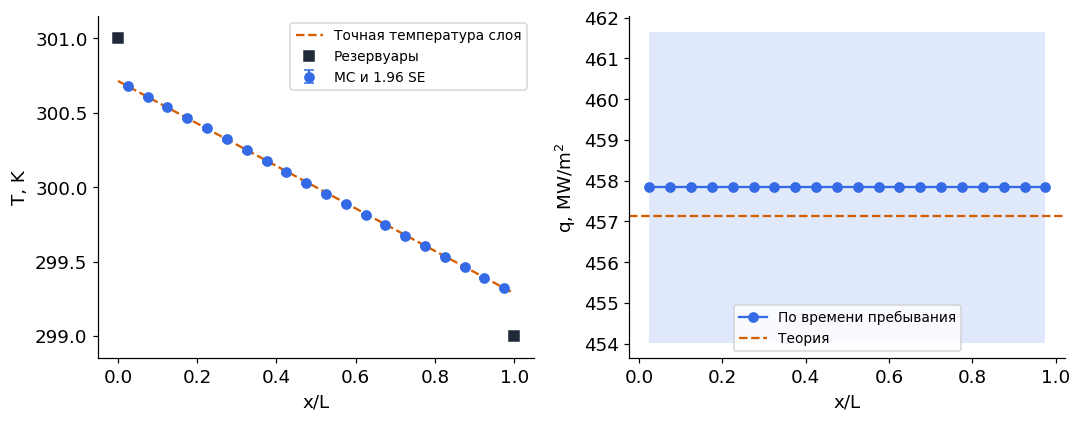

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].errorbar(centers / length, T_mc, yerr=1.96 * T_se,
                 fmt="o", capsize=3, label="MC и 1.96 SE")
grid = np.linspace(0, length, 100)
axes[0].plot(grid / length, TR + DeltaT * (length + 1 - grid) / (length + 2),
             "--", color="#D55E00", label="Точная температура слоя")
axes[0].plot([0, 1], [TL, TR], "s", color="#202938", label="Резервуары")
axes[0].set(xlabel="x/L", ylabel="T, K", ylim=(298.85, 301.15))
axes[0].legend(fontsize=9)
q_cells = q_batches.mean(axis=0)
axes[1].plot(centers / length, q_cells / 1e6, "o-", label="По времени пребывания")
axes[1].axhline(q_exact / 1e6, color="#D55E00", linestyle="--", label="Теория")
axes[1].fill_between(centers / length, (q_mc - 1.96 * q_se) / 1e6,
                     (q_mc + 1.96 * q_se) / 1e6, alpha=0.15)
axes[1].set(xlabel="x/L", ylabel=r"q, MW/m$^2$")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## Граничные скачки
Температура слоя у границы отличается от температуры резервуара, так как встречные потоки не находятся в локальном равновесии. Во всём слое стационарный тепловой поток одинаков. В нашей модели точные профили линейны, поэтому значение в центре ячейки равно среднему по ячейке.

## 边界温度跳跃
边界附近的平板温度不同于热库温度，因为相向的粒子群不处于局域平衡。稳态热流在整个平板中保持一致。本模型的精确温度分布为线性，因此单元中心的值等于单元平均值。

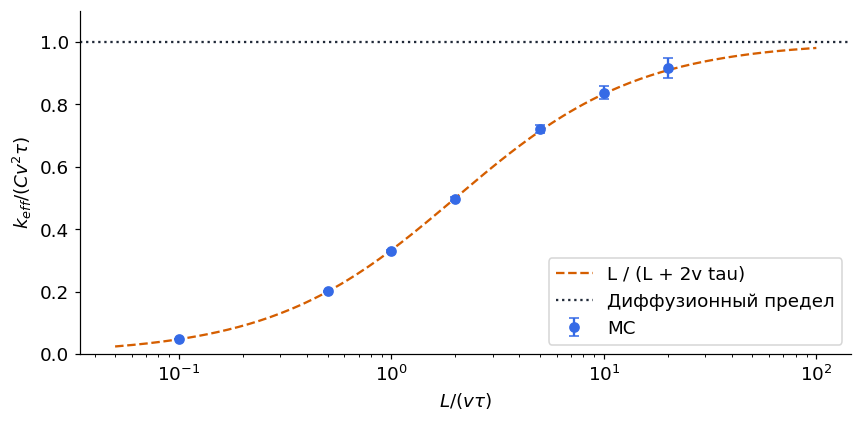

In [6]:
lengths = np.array([0.1, 0.5, 1, 2, 5, 10, 20])
rng_length = np.random.default_rng(2029)
N_length = 30_000
k_ratios, k_se = [], []
for value in lengths:
    result = event_transport(N_length, value, rng_length)
    p = result["transmitted"].mean()
    k_ratios.append(value * p / 2)
    k_se.append(value * np.sqrt(p * (1 - p) / N_length) / 2)
k_ratios, k_se = np.array(k_ratios), np.array(k_se)
grid = np.geomspace(0.05, 100, 200)
fig, ax = plt.subplots()
ax.errorbar(lengths, k_ratios, yerr=1.96 * k_se, fmt="o", capsize=3, label="MC")
ax.semilogx(grid, grid / (grid + 2), "--", label="L / (L + 2v tau)")
ax.axhline(1, color="#202938", linestyle=":", label="Диффузионный предел")
ax.set(xlabel=r"$L/(v\tau)$", ylabel=r"$k_{eff}/(Cv^2\tau)$", ylim=(0, 1.1))
ax.legend()
fig.tight_layout()
plt.show()

## Проверка пределов
Для выбранных двух скоростей $k_{bulk}=Cv^2\tau$. При $L\gg v\tau$ эффективная теплопроводность стремится к этому значению. Коэффициент $1/3$ относится к трёхмерному изотропному распределению направлений и здесь не используется.

Измените $\Delta T$ и проверьте пропорциональность $q$. Затем увеличьте число траекторий и сравните SE.

## 极限检查
对于这里的双速度模型，$k_{bulk}=Cv^2\tau$。当 $L\gg v\tau$ 时，有效热导率趋近该值。三维各向同性方向分布中的 $1/3$ 系数不适用于本模型。

修改 $\Delta T$ 并验证 $q$ 的线性变化，再增加轨迹数并比较 SE。